#  01: Data, EDA & Cleaning







## 0. Setup: imports, paths, constants



In [1]:
import sys                                   # access to Python's module search path
sys.path.append("..")                        # add the project root so that "from src... import ..." works

import re                                    # regular expressions (pattern search in tweets)
import json                                  # save the final cleaning configuration as a .json file
import textwrap                              # wrap long tweets when printing them
import warnings                              # control warning messages
from collections import Counter              # count how many times each word appears

import numpy as np                           # numerical arrays
import pandas as pd                          # DataFrames (tables)
import matplotlib.pyplot as plt              # plotting
import seaborn as sns                        # nicer statistical plots built on matplotlib
from scipy import stats                      # statistical tests (chi-square, Mann-Whitney)
from wordcloud import WordCloud              # WordCloud images

from sklearn.pipeline import Pipeline                                   # chain: vectorizer -> classifier
from sklearn.feature_extraction.text import TfidfVectorizer             # text -> TF-IDF numbers
from sklearn.linear_model import LogisticRegression                     # the fixed model of the experiment
from sklearn.model_selection import StratifiedKFold, cross_val_score    # cross-validation (train only)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score

from src.config import ROOT, RAW_DIR, PROCESSED_DIR, FIGURES_DIR, RANDOM_STATE, LABEL_NAMES, SPLITS   # shared constants (Member B)
from src.data import RAW_PREFIX, load_split, load_mapping                                         # our data loader
from src.cleaning import clean_text, STOPWORDS, NEGATIONS, EMOJI_RE                         # our cleaning function

warnings.filterwarnings("ignore")            # keep the notebook output readable
np.random.seed(RANDOM_STATE)                 # RANDOM_STATE = 42 comes from src/config.py (team contract)

FIG_DIR = FIGURES_DIR                               # every plot is saved here as .png (path from src/config.py)
FIG_DIR.mkdir(parents=True, exist_ok=True)         # create the folder if it does not exist
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)   # create data/processed/ if needed
(ROOT / "results").mkdir(exist_ok=True)    # make sure results/ exists (cleaning_experiment.csv goes there)

sns.set_theme(style="whitegrid", context="notebook")      # global plot style
plt.rcParams["figure.dpi"] = 110                          # sharper images
CLASS_NAMES = LABEL_NAMES                                 # {0: "not_irony", 1: "irony"} from src/config.py
PALETTE = {"not_irony": "#4C72B0", "irony": "#DD8452"}   # one colour per class, reused in every plot
findings = {}                                             # dictionary where we store key numbers for Part 13

def savefig(name):
    """Save the current figure into results/figures/<name>.png and show it."""
    plt.tight_layout()                                              # avoid overlapping labels
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")   # write the PNG file
    plt.show()                                                      # display it in the notebook

print("Project root:", ROOT)

Project root: C:\Users\Mrabet manar\Documents\irony-detection


### 0.1 Check that the raw files are present
`data/raw/` contains the **original TweetEval files, never edited** (shared by the whole team through Git). Before doing anything we verify that all 7 files are there, so a missing file gives a clear message instead of a confusing error later.

In [2]:
expected = [f"{RAW_PREFIX[s]}_{kind}.txt" for s in SPLITS for kind in ("text", "labels")] + ["mapping.txt"]   # the 7 files
missing = [f for f in expected if not (RAW_DIR / f).exists()]       # which ones are not in data/raw/ ?
assert not missing, f"Missing files in {RAW_DIR}: {missing}"        # stop immediately with a clear message
print("data/raw/ is complete:", expected)

data/raw/ is complete: ['train_text.txt', 'train_labels.txt', 'val_text.txt', 'val_labels.txt', 'test_text.txt', 'test_labels.txt', 'mapping.txt']


## 1. Loading the data
In TweetEval, **text and labels are in separate files** (one tweet per line / one label per line). `load_split(name)` in `src/data.py` reads both and returns a DataFrame with columns `text` and `label`. It raises an error if the two files have a different number of lines or if the size is not the official one (**2862 / 955 / 784**), which would mean a line was broken while reading.

In [ ]:
mapping = load_mapping()                              # {0: 'non_irony', 1: 'irony'} read from mapping.txt
print("Label mapping:", mapping)

train = load_split("train", processed=False)                           # official training set      
val   = load_split("validation", processed=False)                             # official validation set    
test  = load_split("test", processed=False)                            # official test set          
dfs = {"train": train, "val": val, "test": test}      # keep them in a dict to loop over them easily
  
for name, df in dfs.items():                          # print the size of each split
    print(f"{name:>5}: {len(df):>5} tweets")
assert (len(train), len(val), len(test)) == (2862, 955, 784)   # hard check against the official sizes
print("Sizes match the official TweetEval irony split.")

Label mapping: {0: 'non_irony', 1: 'irony'}
train:  2862 tweets
  val:   955 tweets
 test:   784 tweets
Sizes match the official TweetEval irony split.


## 2. Overview of the columns: `.info()`, `.head()`, `.describe()`
We start with the **training set**. We want to know: which columns exist, their types, whether values are missing, and how the first rows look.

In [4]:
print("=== train.info() ===")
train.info()                                          # columns, dtypes, non-null counts, memory usage

=== train.info() ===
<class 'pandas.DataFrame'>
RangeIndex: 2862 entries, 0 to 2861
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    2862 non-null   str  
 1   label   2862 non-null   int64
dtypes: int64(1), str(1)
memory usage: 44.8 KB


In [5]:
print("=== train.head(10) ===")
pd.set_option("display.max_colwidth", 140)            # show up to 140 characters of each tweet (default cuts text)
display(train.head(10))                               # first 10 tweets with their label

=== train.head(10) ===


,text,label
0,seeing ppl walking w/ crutches makes me really excited for the next 3 weeks of my life,1
1,"look for the girl with the broken smile, ask her if she wants to stay while, and she will be loved. 💕🎵",0
2,Now I remember why I buy books online @user #servicewithasmile,1
3,@user @user So is he banded from wearing the clothes? #Karma,1
4,Just found out there are Etch A Sketch apps. #oldschool #notoldschool,1
5,"Hey what do you know, one of the witnesses supporting Darren Wilson's story lied! And is racist! Mind blown!",1
6,@user on stage at #flzjingleball at the @user in #Tampa #iheartradio,0
7,You know it's going to be a great day when you're Garmin resets itself and you spill some cinnamon down yourself #slowclap,1
8,Halfway thorough my workday ... Woooo,1
9,Would like to thank my nephew for giving me his horrible cold & sore throat etc.. Much appreciated!,1


In [6]:
print("=== train.describe(include='all') ===")
display(train.describe(include="all"))                # for text: count/unique/top/freq ; for label: mean/std/min/max
print("\nMissing values per column:\n", train.isna().sum())               # NaN count per column
print("\nEmpty / whitespace-only tweets:", (train["text"].str.strip() == "").sum())   # tweets with no content
print("Unique label values:", sorted(train["label"].unique()))             # must be [0, 1]

=== train.describe(include='all') ===


,text,label
count,2862,2862.000000
unique,2862,NaN
top,seeing ppl walking w/ crutches makes me really excited for the next 3 weeks of my life,NaN
freq,1,NaN
mean,NaN,0.504892
std,NaN,0.500063
min,NaN,0.000000
25%,NaN,0.000000
50%,NaN,1.000000
75%,NaN,1.000000



Missing values per column:
 text     0
label    0
dtype: int64

Empty / whitespace-only tweets: 0
Unique label values: [np.int64(0), np.int64(1)]


**Observation.** The dataset has only **two columns**: `text` (string) and `label` (integer 0/1). There are no missing values, so no imputation is needed. `describe()` on the `label` column gives a *mean* equal to the share of ironic tweets (e.g. 0.49 ≈ 49 % ironic) — a quick way to see that the training set is balanced. The text column is a plain string; TweetEval already replaced real user names by `@user` and real links by `http` (anonymisation), which we will exploit during cleaning.

## 3. Class distribution (each split separately)
Why separately? A model is trained on *train* but judged on *val/test*. If the **test set has a different class balance** than train, accuracy alone becomes misleading → this is why we use **macro-F1** as main metric.

In [7]:
rows = []                                                         # we will build a summary table
for name, df in dfs.items():                                      # one row per split
    counts = df["label"].value_counts().sort_index()              # number of tweets for label 0 and 1
    rows.append({
        "split": name,
        "n_tweets": len(df),
        "not_irony (0)": counts[0],
        "irony (1)": counts[1],
        "% not_irony": round(100 * counts[0] / len(df), 1),       # percentage of class 0
        "% irony": round(100 * counts[1] / len(df), 1),           # percentage of class 1
    })
balance = pd.DataFrame(rows).set_index("split")                   # nicer table indexed by split name
display(balance)
findings["balance"] = balance                                     # keep for the final summary

# majority-class baseline: accuracy of a "model" that always answers the most frequent class
for name, df in dfs.items():
    maj = df["label"].value_counts(normalize=True).max()          # share of the biggest class
    print(f"{name:>5}: always predicting the majority class gives accuracy = {maj:.3f}")

,n_tweets,not_irony (0),irony (1),% not_irony,% irony
split,,,,,
train,2862,1417,1445,49.5,50.5
val,955,499,456,52.3,47.7
test,784,473,311,60.3,39.7


train: always predicting the majority class gives accuracy = 0.505
  val: always predicting the majority class gives accuracy = 0.523
 test: always predicting the majority class gives accuracy = 0.603


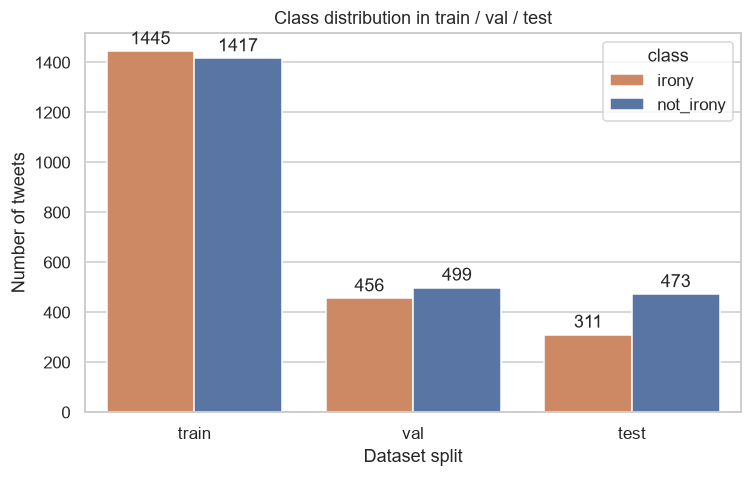

In [ ]:
# Bar chart of class counts for the 3 splits (required by the brief) 
plot_df = (pd.concat({s: d["label"].map(CLASS_NAMES).value_counts() for s, d in dfs.items()}, axis=1)  # counts per split
             .T.reset_index().rename(columns={"index": "split"}))                                       # tidy format
plot_df = plot_df.melt(id_vars="split", var_name="class", value_name="count")                          # long format for seaborn

fig, ax = plt.subplots(figsize=(7, 4.5))                          # one figure, one axis
sns.barplot(data=plot_df, x="split", y="count", hue="class", palette=PALETTE, ax=ax)   # grouped bars
for container in ax.containers:                                   # write the exact count on top of each bar
    ax.bar_label(container, padding=2)
ax.set_title("Class distribution in train / val / test")           # title (required: every plot has one)
ax.set_xlabel("Dataset split")                                    # x-axis label
ax.set_ylabel("Number of tweets")                                 # y-axis label
savefig("01_class_distribution")

In [ ]:
#  Automatic observation (computed from the data, so it is always correct) 
for name, df in dfs.items():
    p = 100 * df["label"].mean()                                  # % of ironic tweets in this split
    print(f"Observation: in {name}, {p:.1f}% of tweets are ironic and {100-p:.1f}% are not.")
gap = abs(100 * test["label"].mean() - 100 * train["label"].mean())
print(f"\nGap train vs test (irony share): {gap:.1f} percentage points.")
if gap > 5:
    print("=> IMPORTANT FINDING: the test set is NOT distributed like train. Accuracy will be misleading; use macro-F1.")

Observation: in train, 50.5% of tweets are ironic and 49.5% are not.
Observation: in val, 47.7% of tweets are ironic and 52.3% are not.
Observation: in test, 39.7% of tweets are ironic and 60.3% are not.

Gap train vs test (irony share): 10.8 percentage points.
=> IMPORTANT FINDING: the test set is NOT distributed like train. Accuracy will be misleading; use macro-F1.


**Observation .** Train and validation are almost perfectly balanced (~50/50), but the **test set contains clearly more non-ironic tweets (~60 %)**. Consequences: (1) a trivial model always answering "non-irony" would already reach ~60 % accuracy on test, so **accuracy is not a reliable yardstick → we use macro-F1**; (2) models may be slightly biased toward predicting "irony" because train is 50/50 while test is not.

## 4. Text length (number of words and characters)
We create two new columns, `n_words` and `n_chars`, in all three splits. Tweets are limited by Twitter (280 characters), so we expect short texts. We then check if **length differs between classes** (if yes, it would be a free feature for models).

In [10]:
for name, df in dfs.items():                                      # same treatment for every split
    df["n_words"] = df["text"].str.split().str.len()              # split on whitespace and count the pieces
    df["n_chars"] = df["text"].str.len()                          # number of characters (spaces included)

print("=== Length statistics (all train tweets) ===")
display(train[["n_words", "n_chars"]].describe().round(2))        # count, mean, std, min, quartiles, max

print("=== Length statistics per class (train) ===")
display(train.groupby(train["label"].map(CLASS_NAMES))[["n_words", "n_chars"]].describe().round(2).T)

# statistical test: is the length difference between the two classes significant?
w0 = train.loc[train.label == 0, "n_words"]                       # word counts of non-ironic tweets
w1 = train.loc[train.label == 1, "n_words"]                       # word counts of ironic tweets
u, p = stats.mannwhitneyu(w0, w1)                                 # non-parametric test (no normality assumption)
print(f"Mean words: not_irony={w0.mean():.2f}  irony={w1.mean():.2f}   Mann-Whitney p-value={p:.4f}")
findings["len_means"] = (w0.mean(), w1.mean(), p)                 # keep for the summary

=== Length statistics (all train tweets) ===


,n_words,n_chars
count,2862.00,2862.00
mean,13.61,79.25
std,6.69,37.12
min,1.00,6.00
25%,9.00,52.00
50%,13.00,78.00
75%,18.00,106.00
max,177.00,1000.00


=== Length statistics per class (train) ===


label            irony  not_irony
n_words count  1445.00    1417.00
        mean     13.50      13.71
        std       5.98       7.35
        min       1.00       1.00
        25%       9.00       9.00
        50%      13.00      13.00
        75%      18.00      18.00
        max      29.00     177.00
n_chars count  1445.00    1417.00
        mean     78.23      80.29
        std      33.23      40.70
        min       6.00       7.00
        25%      51.00      53.00
        50%      77.00      80.00
        75%     107.00     105.00
        max     137.00    1000.00

Mean words: not_irony=13.71  irony=13.50   Mann-Whitney p-value=0.9229


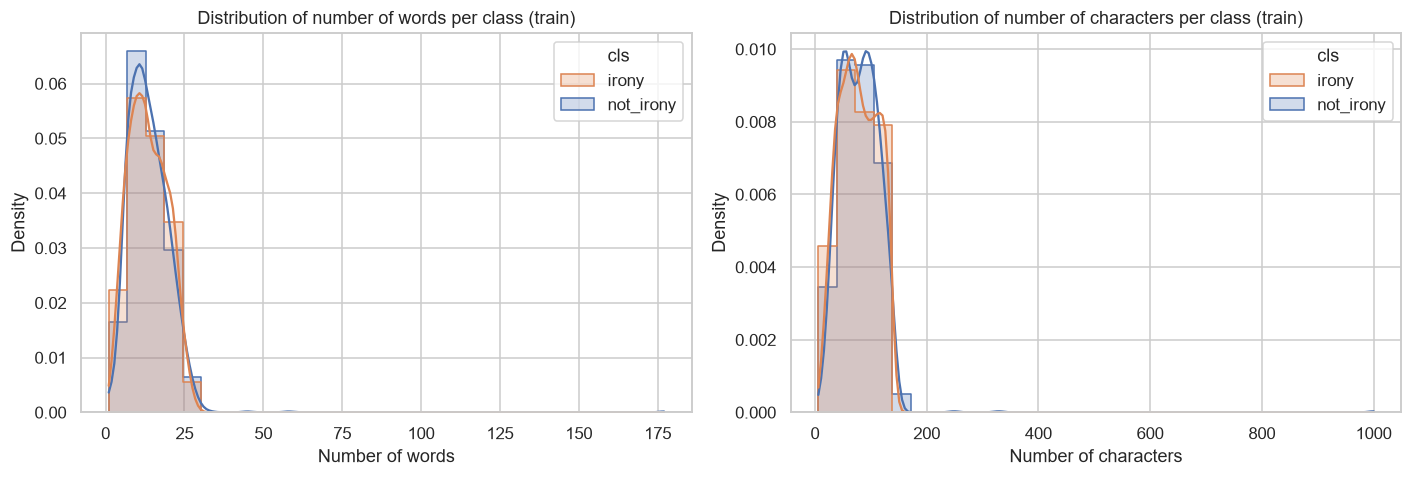

In [ ]:
#  Histograms: number of words and characters, one histogram per class, overlaid 
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))                 # two plots side by side
for ax, col, label in zip(axes, ["n_words", "n_chars"], ["Number of words", "Number of characters"]):
    sns.histplot(data=train.assign(cls=train["label"].map(CLASS_NAMES)),   # add a readable class column
                 x=col, hue="cls", palette=PALETTE, bins=30, kde=True,    # kde = smooth density curve
                 element="step", stat="density", common_norm=False, ax=ax) # density so classes are comparable
    ax.set_title(f"Distribution of {label.lower()} per class (train)")     # title
    ax.set_xlabel(label)                                                   # x label
    ax.set_ylabel("Density")                                               # y label
savefig("02_length_histograms")

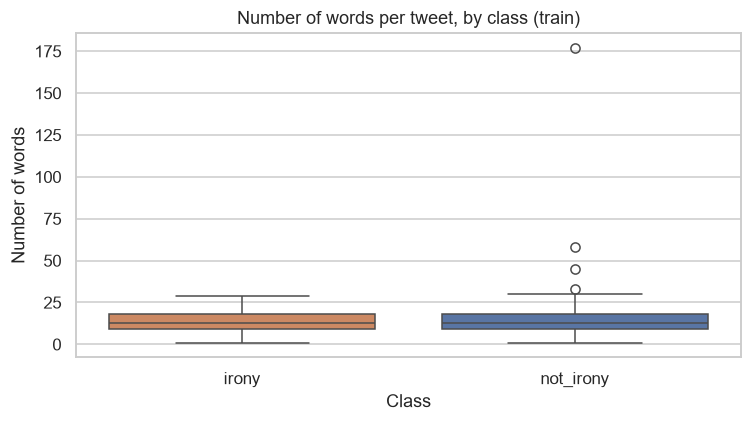

Observation: the average tweet has 13.6 words / 79 characters; ironic tweets average 13.5 words vs 13.7 for non-ironic tweets (difference NOT significant at 5%, p=0.923).
Longest tweet: 1000 characters | shortest: 6 characters.


In [ ]:
#  Boxplot: another view of the same information (shows medians and outliers) 
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=train.assign(cls=train["label"].map(CLASS_NAMES)), x="cls", y="n_words", palette=PALETTE, ax=ax)
ax.set_title("Number of words per tweet, by class (train)")
ax.set_xlabel("Class")
ax.set_ylabel("Number of words")
savefig("03_length_boxplot")

print(f"Observation: the average tweet has {train.n_words.mean():.1f} words / {train.n_chars.mean():.0f} characters; "
      f"ironic tweets average {w1.mean():.1f} words vs {w0.mean():.1f} for non-ironic tweets "
      f"(difference {'significant' if p < 0.05 else 'NOT significant'} at 5%, p={p:.3f}).")
print("Longest tweet:", train.n_chars.max(), "characters | shortest:", train.n_chars.min(), "characters.")

**Observation.** Tweets are short (roughly 10–20 words, ≈ 100 characters). The two class distributions overlap strongly, so **length alone cannot separate irony from non-irony**: any real signal must come from *content* and *style*, not from size. This also tells us that very short documents give TF-IDF very few non-zero values, which makes the task hard for bag-of-words models.

## 5. WordClouds and most frequent words per class
A WordCloud draws frequent words bigger. For readability we only use the **train** tweets, lowercase them, drop stopwords and the placeholders `user`, `http` (they appear in every tweet and carry no meaning).

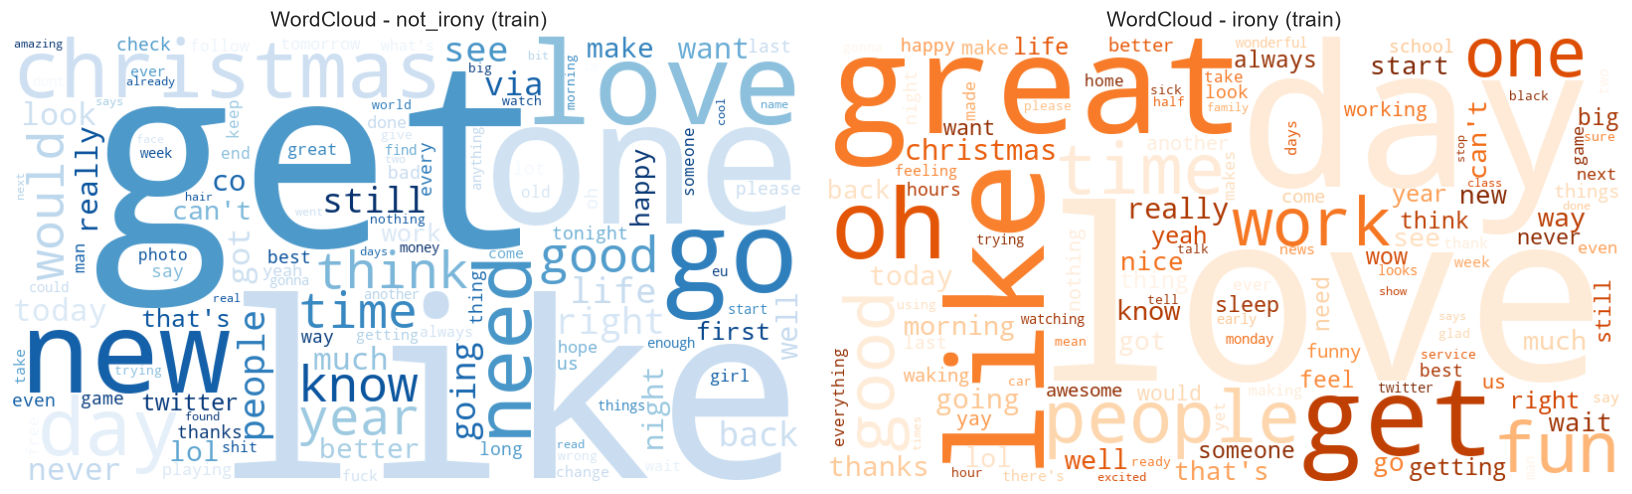

In [13]:
PLACEHOLDERS = {"user", "http", "https", "amp", "rt"}            # tokens that are noise for a visual / frequency analysis
VIS_STOP = set(STOPWORDS) | PLACEHOLDERS                         # stopwords + placeholders

def tokens_for_vis(text):
    """Lowercase a tweet, keep only alphabetic words (and apostrophes), drop stopwords/placeholders."""
    words = re.findall(r"[a-z']+", text.lower())                 # extract words made of letters / apostrophes
    return [w for w in words if w not in VIS_STOP and len(w) > 1]   # remove stopwords and 1-letter tokens

tokens = {c: [] for c in (0, 1)}                                 # list of words per class
for text, label in zip(train["text"], train["label"]):           # loop over train tweets
    tokens[label].extend(tokens_for_vis(text))                   # add the tweet's words to its class
freq = {c: Counter(tokens[c]) for c in (0, 1)}                   # word -> count, per class

fig, axes = plt.subplots(1, 2, figsize=(15, 6))                  # one WordCloud per class
for ax, c in zip(axes, (0, 1)):
    wc = WordCloud(width=800, height=450, background_color="white", max_words=120,
                   colormap="Blues" if c == 0 else "Oranges", random_state=RANDOM_STATE)   # reproducible layout
    wc.generate_from_frequencies(freq[c])                        # build the cloud from word counts
    ax.imshow(wc, interpolation="bilinear")                      # draw it
    ax.axis("off")                                               # no axes for an image
    ax.set_title(f"WordCloud - {CLASS_NAMES[c]} (train)", fontsize=14)
savefig("04_wordclouds")

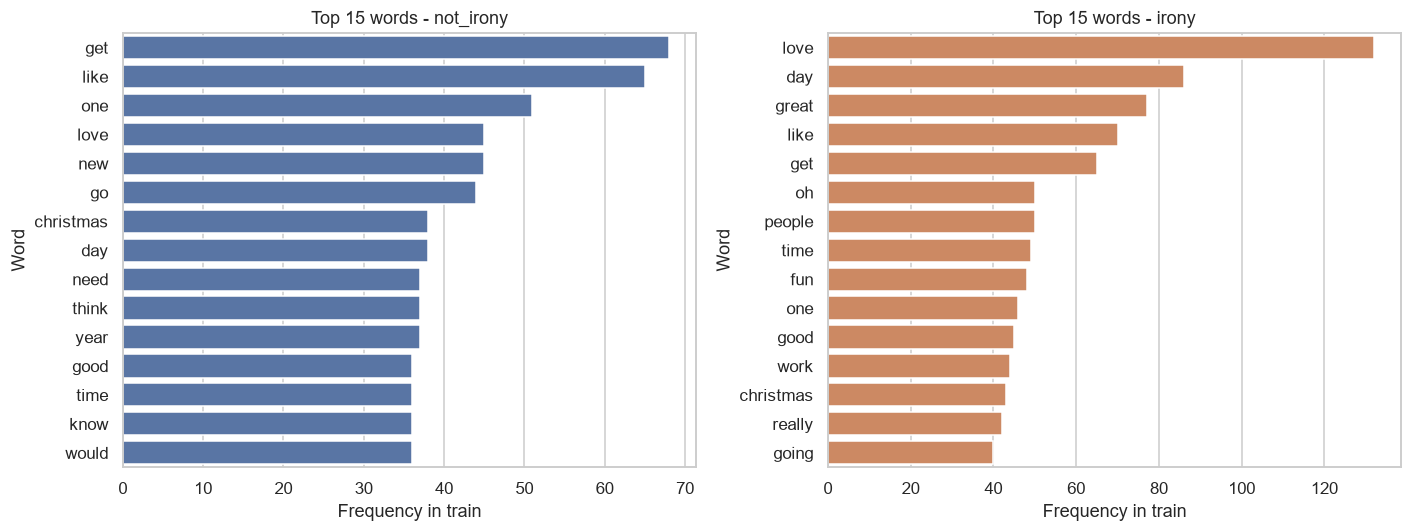

Observation: 8 of the 15 most frequent words are shared by both classes: ['christmas', 'day', 'get', 'good', 'like', 'love', 'one', 'time']


In [ ]:
#  Top-15 most frequent words per class, side by side 
top = {c: freq[c].most_common(15) for c in (0, 1)}               # 15 most common (word, count) pairs per class
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, c in zip(axes, (0, 1)):
    words, counts = zip(*top[c])                                 # unzip pairs into two tuples
    sns.barplot(x=list(counts), y=list(words), color=PALETTE[CLASS_NAMES[c]], ax=ax)   # horizontal bars
    ax.set_title(f"Top 15 words - {CLASS_NAMES[c]}")
    ax.set_xlabel("Frequency in train")
    ax.set_ylabel("Word")
savefig("05_top_words")

common = set(w for w, _ in top[0]) & set(w for w, _ in top[1])   # words that are in both top-15 lists
print(f"Observation: {len(common)} of the 15 most frequent words are shared by both classes: {sorted(common)}")

In [ ]:
#  Words that are most DISTINCTIVE of each class (log-ratio of smoothed relative frequencies) 
N0, N1 = sum(freq[0].values()), sum(freq[1].values())            # total number of words in each class
vocab = set(freq[0]) | set(freq[1])                              # all words seen in train
V = len(vocab)                                                   # vocabulary size (for add-one smoothing)
rows = []
for w in vocab:
    c0, c1 = freq[0][w], freq[1][w]                              # count of w in each class
    if c0 + c1 < 15:                                             # ignore rare words (their ratio is unreliable)
        continue
    ratio = np.log(((c1 + 1) / (N1 + V)) / ((c0 + 1) / (N0 + V)))   # >0 : more typical of irony ; <0 : of non-irony
    rows.append((w, c0, c1, ratio))
dist = pd.DataFrame(rows, columns=["word", "count_not_irony", "count_irony", "log_ratio"]).sort_values("log_ratio")
print("Most typical of NON-IRONY:"); display(dist.head(12).reset_index(drop=True))
print("Most typical of IRONY:");     display(dist.tail(12).iloc[::-1].reset_index(drop=True))

Most typical of NON-IRONY:


,word,count_not_irony,count_irony,log_ratio
0,co,26,4,-1.692841
1,what's,14,2,-1.615880
2,eu,13,2,-1.546888
3,check,17,3,-1.510520
4,photo,15,3,-1.392737
5,via,31,8,-1.274954
6,follow,15,4,-1.169593
7,long,17,5,-1.105055
8,girl,16,5,-1.047896
9,im,12,4,-0.961954


Most typical of IRONY:


,word,count_not_irony,count_irony,log_ratio
0,waking,0,18,2.937997
1,yay,2,19,1.890678
2,wonderful,2,13,1.534003
3,monday,2,13,1.534003
4,early,2,13,1.534003
5,great,16,77,1.517053
6,fun,10,48,1.487483
7,hours,4,17,1.274491
8,working,5,19,1.197530
9,service,3,12,1.172213


**Observation.** The two WordClouds look **very similar**: the dominant words (`like`, `just`, `get`, `love`, `day`, …) appear in both classes. This is a *finding*, not a failure: irony is **not about which words appear**, it is about the *contrast* between words and situation. It warns us that a pure bag-of-words model will struggle, and it motivates the transformer (which reads context) used by Member D. The "distinctive words" table shows that only a handful of words lean toward one class, and with weak ratios.

## 6. Irony-specific checks
These checks decide **which cleaning steps are dangerous**. If a character or pattern is more frequent in ironic tweets, deleting it would destroy a signal (the brief warns: *« négations, mots vides, hashtags, majuscules peuvent porter de l'information utile »*).

### 6.1 Hashtags, mentions and links
The ironic tweets were originally collected with the hashtags `#irony`, `#sarcasm`, `#not`, which TweetEval **removed**. We check whether some leaked through (a model could then "cheat").

In [16]:
LEAK_RE = r"#(?:not|sarcasm|sarcastic|irony|ironic|sarcasm_)\b"    # hashtags that directly reveal the label

def share(series):
    """Percentage of True values in a boolean Series."""
    return round(100 * series.mean(), 1)

d = train.copy()                                                  # work on a copy of train
d["cls"] = d["label"].map(CLASS_NAMES)                            # readable class names
d["has_hashtag"] = d["text"].str.contains("#", regex=False)       # at least one '#'
d["has_leak_tag"] = d["text"].str.contains(LEAK_RE, case=False, regex=True)   # a label-revealing hashtag left behind
d["has_mention"] = d["text"].str.contains("@user", regex=False)   # anonymised mention
d["has_url"] = d["text"].str.contains(r"\bhttps?\b", case=False, regex=True)  # anonymised link ("http")

summary = d.groupby("cls")[["has_hashtag", "has_leak_tag", "has_mention", "has_url"]].mean().mul(100).round(1)
print("% of tweets containing each element (train):")
display(summary)

all_tags = d["text"].str.findall(r"#\w+").explode().dropna().str.lower()    # every hashtag in the data, lowercased
print("\nTotal hashtag occurrences:", len(all_tags), "| distinct hashtags:", all_tags.nunique())
print("Top 15 hashtags:", all_tags.value_counts().head(15).to_dict())
print("\nLeaked label-revealing hashtags in train/val/test:",
      {n: int(df["text"].str.contains(LEAK_RE, case=False, regex=True).sum()) for n, df in dfs.items()})
findings["hashtag_share"] = share(d["has_hashtag"])
findings["leak_tags"] = int(d["has_leak_tag"].sum())

% of tweets containing each element (train):


,has_hashtag,has_leak_tag,has_mention,has_url
cls,,,,
irony,37.2,0.0,32.8,0.2
not_irony,40.0,0.0,46.2,1.4



Total hashtag occurrences: 2740 | distinct hashtags: 2144
Top 15 hashtags: {'#a': 15, '#christmas': 14, '#the': 12, '#love': 12, '#is': 12, '#to': 10, '#ferguson': 10, '#lol': 9, '#eu': 9, '#funny': 8, '#you': 7, '#new': 7, '#notcies': 6, '#tcot': 6, '#work': 6}

Leaked label-revealing hashtags in train/val/test: {'train': 0, 'val': 0, 'test': 431}


### 6.2 Style signals: `!`, `?`, `...`, emojis, ALL-CAPS, elongated words, quotes
For every signal we compute the **share of tweets containing it, per class**, and a **chi-square test** (is the difference between classes larger than chance?).

In [17]:
signals = {                                                       # name -> regular expression applied to the RAW text
    "exclamation '!'":       r"!",                                # any exclamation mark
    "multiple '!!'":         r"!{2,}",                            # repeated exclamation marks
    "question '?'":          r"\?",                               # any question mark
    "ellipsis '...'":        r"\.{2,}|…",                         # "..." or the single character "…"
    "ALL-CAPS word":         r"\b[A-Z]{2,}\b",                    # a word of 2+ capital letters ("GREAT")
    "elongation (sooo)":     r"(\w)\1{2,}",                       # a character repeated 3+ times
    "quotation marks":       r"[\"“”]",                           # quoted words are a classic sarcasm marker
}
sig = pd.DataFrame({name: d["text"].str.contains(rx, regex=True) for name, rx in signals.items()})   # boolean table
sig["emoji"] = d["text"].apply(lambda t: bool(EMOJI_RE.search(t)))   # emoji presence (uses the regex from cleaning.py)
sig["cls"] = d["cls"]                                             # add the class column

rows = []
for col in [c for c in sig.columns if c != "cls"]:                # one row per signal
    ct = pd.crosstab(sig[col], sig["cls"])                        # 2x2 contingency table (signal yes/no x class)
    p = stats.chi2_contingency(ct)[1] if ct.shape == (2, 2) else np.nan   # p-value of the chi-square test
    rows.append({"signal": col,
                 "% not_irony": round(100 * sig.loc[sig.cls == "not_irony", col].mean(), 1),
                 "% irony":     round(100 * sig.loc[sig.cls == "irony", col].mean(), 1),
                 "p-value": round(p, 4)})
sig_table = pd.DataFrame(rows).set_index("signal")
sig_table["diff (irony - non)"] = (sig_table["% irony"] - sig_table["% not_irony"]).round(1)   # + => more frequent in irony
sig_table["significant (p<0.05)"] = sig_table["p-value"] < 0.05
display(sig_table)
findings["signals"] = sig_table

,% not_irony,% irony,p-value,diff (irony - non),significant (p<0.05)
signal,,,,,
exclamation '!',17.1,17.2,0.9926,0.1,False
multiple '!!',4.2,4.6,0.6658,0.4,False
question '?',13.3,9.3,0.0009,-4.0,True
ellipsis '...',16.4,15.8,0.7406,-0.6,False
ALL-CAPS word,17.9,14.0,0.0046,-3.9,True
elongation (sooo),2.8,4.2,0.0541,1.4,False
quotation marks,4.7,5.5,0.3711,0.8,False
emoji,12.6,9.3,0.0048,-3.3,True


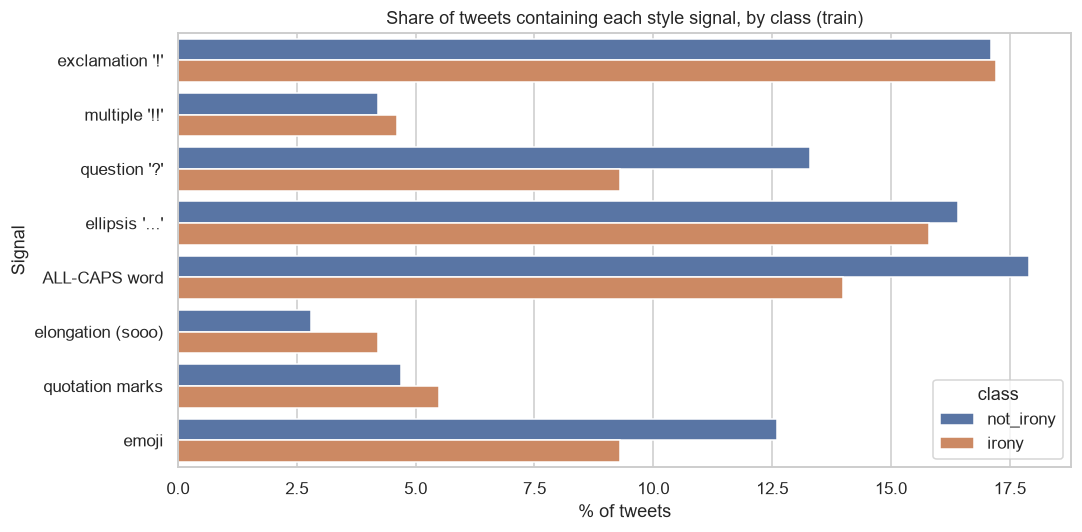

Signals significantly different between classes: ["question '?'", 'ALL-CAPS word', 'emoji']
 - question '?': more frequent in non-ironic tweets (9.3% vs 13.3%)
 - ALL-CAPS word: more frequent in non-ironic tweets (14.0% vs 17.9%)
 - emoji: more frequent in non-ironic tweets (9.3% vs 12.6%)


In [ ]:
# Plot: share of tweets with each signal, per class 
plot_sig = sig_table[["% not_irony", "% irony"]].reset_index().melt(id_vars="signal", var_name="class", value_name="percent")
plot_sig["class"] = plot_sig["class"].str.replace("% ", "", regex=False)      # "% irony" -> "irony"
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=plot_sig, y="signal", x="percent", hue="class", palette=PALETTE, ax=ax)
ax.set_title("Share of tweets containing each style signal, by class (train)")
ax.set_xlabel("% of tweets")
ax.set_ylabel("Signal")
savefig("06_irony_signals")

sigsig = sig_table[sig_table["significant (p<0.05)"]]            # only the signals that differ significantly
print("Signals significantly different between classes:", list(sigsig.index))
for name, r in sigsig.iterrows():
    who = "ironic" if r["diff (irony - non)"] > 0 else "non-ironic"
    print(f" - {name}: more frequent in {who} tweets ({r['% irony']}% vs {r['% not_irony']}%)")

**Observation.** The signals that are *significantly* more frequent in one class tell us which characters must **not** be removed. Whenever a signal (`!`, `?`, `...`, emojis, CAPS, quotes) is more frequent in ironic tweets, **removing punctuation/emojis or lowercasing deletes real evidence**. This is the hypothesis we test *quantitatively* in Part 11 instead of guessing. If no hashtag such as `#not` / `#sarcasm` is left over (check the "Leaked" line above), there is no label leakage through hashtags.

## 7. Duplicates and overlap between splits
Duplicates inflate scores (the model may have *seen* the test tweet during training) and conflicting duplicates (same text, different label) show label noise.

In [19]:
print("Duplicated tweets inside each split:")
for name, df in dfs.items():
    print(f"  {name:>5}: {df['text'].duplicated().sum()} duplicated rows")

conflict = train.groupby("text")["label"].nunique()               # number of distinct labels per identical text
conflict = conflict[conflict > 1]                                 # keep texts with BOTH labels
print("\nIdentical tweets with conflicting labels (train):", len(conflict))

sets = {n: set(df["text"]) for n, df in dfs.items()}              # set of distinct texts per split
overlap = {"train & val": len(sets["train"] & sets["val"]),       # intersection sizes
           "train & test": len(sets["train"] & sets["test"]),
           "val & test": len(sets["val"] & sets["test"])}
print("\nExact tweets present in two splits:", overlap)
findings["dups"] = (int(train["text"].duplicated().sum()), overlap)

leak = sets["train"] & sets["test"]                               # tweets that appear both in train and test
if leak:
    print("\nExamples of train/test overlap:")
    for t in list(leak)[:5]:
        print("  -", t)

Duplicated tweets inside each split:
  train: 0 duplicated rows
    val: 0 duplicated rows
   test: 0 duplicated rows

Identical tweets with conflicting labels (train): 0

Exact tweets present in two splits: {'train & val': 0, 'train & test': 0, 'val & test': 0}


**Observation.** We only report duplicates; we do **not** remove them, because the brief and our team contract require using the **official** train/val/test files unchanged (everyone must be evaluated on exactly the same tweets). Overlap between train and test, if any, is small and is mentioned as a limitation.

## 8. Reading 20 random tweets per class
Charts do not show everything. We read real examples (random, `random_state=42`) to notice what the numbers miss — for instance ironic tweets whose ending "feels missing" because the flipping hashtag (`#not`) was removed.

In [20]:
for label in (1, 0):                                              # first ironic, then non-ironic
    print("=" * 100)
    print(f"20 RANDOM TWEETS - {CLASS_NAMES[label].upper()}")
    print("=" * 100)
    sample = train[train["label"] == label].sample(20, random_state=RANDOM_STATE)   # reproducible random sample
    for i, t in enumerate(sample["text"], 1):                     # numbered list
        print(f"{i:>2}. " + textwrap.fill(t, width=95, subsequent_indent="    "))   # wrap long tweets

20 RANDOM TWEETS - IRONY
 1. @user thanks for leaving the dish for us  #badbusiness
 2. @user @user Spoiled, rancid food AND guns in the aisles? Rats in @user great.
    #GroceriesNotGuns
 3. People at my school only talk about sex and drugs. So awesome
 4. @user Ha! I don't have haters. Just a few misguided souls who thought my mentions were a
    bulletin board for their issues. ;)
 5. Well the week is off to a great start.  #fml
 6. You're great at keeping a conversation. .
 7. Can't wait for my 7:30am #dental appointment tomorrow!|Oh time please speed through today! !
 8. Love waking up early in the morning  #HockeyTournament #RefLife #Zebras
 9. Pulis is available. Will guarantee we stay up
10. Everyone competing against each other for privatized goods is way better than working together
    as a whole to advance humanity.
11. Done to much again
12. Yes it is much more logical to support criminals & attack police officers for protecting life &
    property. #HandsUpDontShoot
13. P

**Qualitative notes (fill in after reading, 3–4 sentences).** Typical things to look for: *positive words describing a negative situation* ("Great, another Monday"), *exaggeration and CAPS*, *rhetorical questions*, *emojis that contradict the text*, tweets that seem **incomplete** because a hashtag was deleted, and **non-ironic tweets that look sarcastic** (label noise). 

In [21]:
def save_processed(config):
    """Apply clean_text(**config) to every split with the SAME function and write data/processed/<split>.csv."""
    for name in SPLITS:                                           # train, val, test
        raw = load_split(name, processed=False)                                    # reload the pristine raw data
        raw["text_clean"] = raw["text"].apply(lambda t: clean_text(t, **config))   # same function for all splits
        raw[["text", "text_clean", "label"]].to_csv(PROCESSED_DIR / f"{name}.csv", index=False, encoding="utf-8")
        print(f"saved {name}.csv  ({len(raw)} rows)")

ROUGH_CONFIG = dict(remove_urls=True, remove_mentions=True)       # only links + mentions; everything else stays untouched
save_processed(ROUGH_CONFIG)

saved train.csv  (2862 rows)
saved validation.csv  (955 rows)
saved test.csv  (784 rows)


## 10. The cleaning function and what each step does
`clean_text()` (in `src/cleaning.py`) has **one ON/OFF switch per step**, so the effect of each step can be measured alone.

| Switch | Effect | Risk for irony |
|---|---|---|
| `remove_urls` | removes `http` / links | none (noise) |
| `remove_mentions` | removes `@user` | none (noise) |
| `hashtags` | `"keep"`, `"strip"` (`#word`→`word`), `"remove"` | some hashtags carry tone (`#blessed`) |
| `lowercase` | `GREAT` → `great` | loses sarcastic shouting |
| `remove_emojis` | deletes emojis | emoji after a complaint = irony marker |
| `remove_stopwords` (+`keep_negations`) | deletes `the, is, and…` | default lists contain **not / no / never** |
| `remove_punctuation` | deletes `!!! ... ?` | punctuation is an irony signal |
| `lemmatize` | `running` → `run` | merges word forms (needs NLTK WordNet) |

**Why TF-IDF must also be configured carefully:** scikit-learn's `TfidfVectorizer` lowercases text and ignores punctuation/emojis *by default*, which would silently cancel our experiment. In Part 11 we therefore set `lowercase=False` and a `token_pattern` that keeps punctuation and emojis as tokens.

In [ ]:
#  Show the effect of each step on the same tweet 
example = "@user Oh GREAT!!! My phone died right before the exam... #blessed 😂 http I'm not happy, don't care"
steps = {
    "original":                   dict(remove_urls=False, remove_mentions=False),
    "links + mentions removed":   dict(),
    "+ lowercase":                dict(lowercase=True),
    "+ hashtag symbol stripped":  dict(hashtags="strip"),
    "+ hashtag removed":          dict(hashtags="remove"),
    "+ emojis removed":           dict(remove_emojis=True),
    "+ punctuation removed":      dict(remove_punctuation=True),
    "+ ALL stopwords removed":    dict(remove_stopwords=True, keep_negations=False),
    "+ stopwords (negations kept)": dict(remove_stopwords=True, keep_negations=True),
    "+ lemmatized":               dict(lemmatize=True),
}
for name, cfg in steps.items():                                   # apply each switch ALONE to the example
    print(f"{name:<30} -> {clean_text(example, **cfg)}")
print("\nNote how 'not' and \"don't\" disappear when keep_negations=False: that would turn 'not happy' into 'happy'!")
print("Stopword list contains 'not'?", "not" in STOPWORDS, "| contains \"don't\"?", "don't" in STOPWORDS)

original                       -> @user Oh GREAT!!! My phone died right before the exam... #blessed 😂 http I'm not happy, don't care
links + mentions removed       -> Oh GREAT!!! My phone died right before the exam... #blessed 😂 I'm not happy, don't care
+ lowercase                    -> oh great!!! my phone died right before the exam... #blessed 😂 i'm not happy, don't care
+ hashtag symbol stripped      -> Oh GREAT!!! My phone died right before the exam... blessed 😂 I'm not happy, don't care
+ hashtag removed              -> Oh GREAT!!! My phone died right before the exam... 😂 I'm not happy, don't care
+ emojis removed               -> Oh GREAT!!! My phone died right before the exam... #blessed I'm not happy, don't care
+ punctuation removed          -> Oh GREAT My phone died right before the exam blessed 😂 Im not happy dont care
+ ALL stopwords removed        -> Oh GREAT!!! phone died right exam... #blessed 😂 happy, care
+ stopwords (negations kept)   -> Oh GREAT!!! phone died right 

## 11. The cleaning experiment — measuring instead of guessing
**Protocol (strict):**
1. Fix **one simple model**: `TF-IDF + Logistic Regression`, identical settings every time .
2. **Train on `train`, score on `val`.** The test set is **never touched** (choosing cleaning by looking at test would be leakage through *decisions*).
3. Change **one cleaning step at a time** and record macro-F1 (our main metric), plus accuracy / precision / recall.
4. Vectorizer and model live in a `Pipeline`, so TF-IDF is *fitted on the training tweets only*.
5. As extra evidence we also report a 5-fold cross-validated macro-F1 on **train only** (more stable than one validation score: val has only 955 tweets, so differences below ≈ 0.01 are within noise).

In [23]:
def make_model():
    """Fixed model for every experiment: TF-IDF (words + word pairs) followed by Logistic Regression."""
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=False,                       # IMPORTANT: do NOT let sklearn lowercase; our cleaning decides
            token_pattern=r"[\w']+|[^\w\s]",       # words (with apostrophes) AND single punctuation/emoji symbols as tokens
            ngram_range=(1, 2),                    # single words + word pairs ("not happy")
            min_df=2,                              # ignore tokens appearing in fewer than 2 tweets (typos, one-offs)
            sublinear_tf=True)),                   # dampen words repeated within one tweet
        ("clf", LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE)),   # same seed everywhere
    ])

y_train = train["label"].values                    # training labels
y_val = val["label"].values                        # validation labels (test labels are NOT used here)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # 5 folds keeping class balance

def run_version(name, config):
    """Clean train and val with `config`, fit on train, score on val. Returns one dict of metrics."""
    Xtr = train["text"].apply(lambda t: clean_text(t, **config))   # clean the training tweets
    Xva = val["text"].apply(lambda t: clean_text(t, **config))     # clean the validation tweets with the SAME function
    model = make_model().fit(Xtr, y_train)                         # TF-IDF fitted on train only, then LogReg
    pred = model.predict(Xva)                                      # predict validation labels
    p, r, f1_irony, _ = precision_recall_fscore_support(y_val, pred, average="binary", pos_label=1, zero_division=0)
    cv_f1 = cross_val_score(make_model(), Xtr, y_train, cv=cv, scoring="f1_macro").mean()   # train-only CV
    return {"cleaning_version": name,
            "val_macro_f1": f1_score(y_val, pred, average="macro"),     # MAIN METRIC
            "val_accuracy": accuracy_score(y_val, pred),
            "val_precision_irony": p, "val_recall_irony": r, "val_f1_irony": f1_irony,
            "cv5_macro_f1_train": cv_f1,
            "config": json.dumps(config, sort_keys=True)}               # keep the exact settings

RAW_CFG = dict(remove_urls=False, remove_mentions=False)           # "no cleaning at all"
BASE_CFG = dict(remove_urls=True, remove_mentions=True)            # baseline = only the always-safe steps
print("Experiment helpers ready.")

Experiment helpers ready.


### 11.1 Experiment 1 — cumulative (each row adds a step to the previous one)
This is the table shown in the guide: it reads like a story, from raw text to heavy cleaning.

In [24]:
cumulative = [                                                    # (label, full config) — each config extends the previous one
    ("Raw text",                          RAW_CFG),
    ("+ remove links & mentions",         BASE_CFG),
    ("+ lowercase",                       {**BASE_CFG, "lowercase": True}),
    ("+ strip '#' from hashtags",         {**BASE_CFG, "lowercase": True, "hashtags": "strip"}),
    ("+ remove punctuation",              {**BASE_CFG, "lowercase": True, "hashtags": "strip", "remove_punctuation": True}),
    ("+ remove ALL stopwords (incl. not)", {**BASE_CFG, "lowercase": True, "hashtags": "strip", "remove_punctuation": True,
                                            "remove_stopwords": True, "keep_negations": False}),
]
exp1 = pd.DataFrame([run_version(n, c) for n, c in cumulative])   # run every version
display(exp1.drop(columns="config").round(4))

,cleaning_version,val_macro_f1,val_accuracy,val_precision_irony,val_recall_irony,val_f1_irony,cv5_macro_f1_train
0,Raw text,0.6245,0.6251,0.6065,0.6118,0.6092,0.6479
1,+ remove links & mentions,0.6250,0.6251,0.6017,0.6360,0.6183,0.6317
2,+ lowercase,0.6331,0.6335,0.6132,0.6294,0.6212,0.6409
3,+ strip '#' from hashtags,0.6272,0.6272,0.6020,0.6469,0.6237,0.6308
4,+ remove punctuation,0.6324,0.6325,0.6087,0.6447,0.6262,0.6206
5,+ remove ALL stopwords (incl. not),0.6171,0.6178,0.5991,0.6031,0.6011,0.6121


### 11.2 Experiment 2 — one step at a time on top of the baseline
Here every step is added **alone** to the baseline (links + mentions removed), so its individual effect is isolated (Experiment 1 mixes the effects of several steps).

In [25]:
single_steps = {                                                  # name -> the ONE change applied to BASE_CFG
    "baseline (links+mentions removed)": {},
    "lowercase":                         {"lowercase": True},
    "hashtags: strip '#'":               {"hashtags": "strip"},
    "hashtags: remove entirely":         {"hashtags": "remove"},
    "remove emojis":                     {"remove_emojis": True},
    "remove punctuation":                {"remove_punctuation": True},
    "stopwords removed (incl. negations)": {"remove_stopwords": True, "keep_negations": False},
    "stopwords removed (negations kept)":  {"remove_stopwords": True, "keep_negations": True},
    "lemmatize":                         {"lemmatize": True},
}
exp2 = pd.DataFrame([run_version(n, {**BASE_CFG, **chg}) for n, chg in single_steps.items()])
base_f1 = exp2.loc[0, "val_macro_f1"]                             # macro-F1 of the baseline
exp2["delta_vs_baseline"] = exp2["val_macro_f1"] - base_f1        # + : the step helps ; - : the step hurts
display(exp2.drop(columns="config").round(4))

,cleaning_version,val_macro_f1,val_accuracy,val_precision_irony,val_recall_irony,val_f1_irony,cv5_macro_f1_train,delta_vs_baseline
0,baseline (links+mentions removed),0.6250,0.6251,0.6017,0.6360,0.6183,0.6317,0.0000
1,lowercase,0.6331,0.6335,0.6132,0.6294,0.6212,0.6409,0.0081
2,hashtags: strip '#',0.6136,0.6136,0.5893,0.6294,0.6087,0.6251,-0.0115
3,hashtags: remove entirely,0.6197,0.6199,0.5971,0.6272,0.6118,0.6222,-0.0053
4,remove emojis,0.6239,0.6241,0.6017,0.6294,0.6152,0.6282,-0.0011
5,remove punctuation,0.6177,0.6178,0.5934,0.6338,0.6129,0.6088,-0.0073
6,stopwords removed (incl. negations),0.6250,0.6251,0.6021,0.6338,0.6175,0.6136,-0.0000
7,stopwords removed (negations kept),0.6227,0.6230,0.6017,0.6228,0.6121,0.6174,-0.0023
8,lemmatize,0.6371,0.6377,0.6196,0.6250,0.6223,0.6447,0.0121


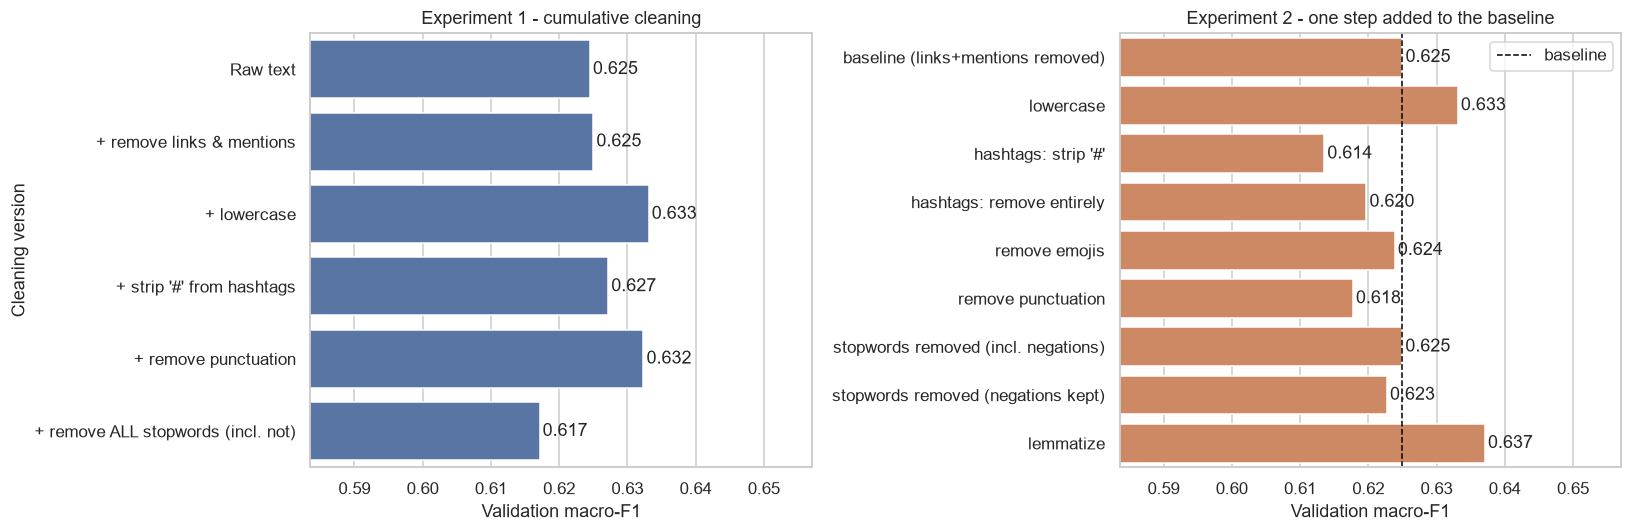

In [26]:
# ---- Plot both experiments ----
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=exp1, y="cleaning_version", x="val_macro_f1", color="#4C72B0", ax=axes[0])
axes[0].set_title("Experiment 1 - cumulative cleaning"); axes[0].set_xlabel("Validation macro-F1"); axes[0].set_ylabel("Cleaning version")
sns.barplot(data=exp2, y="cleaning_version", x="val_macro_f1", color="#DD8452", ax=axes[1])
axes[1].set_title("Experiment 2 - one step added to the baseline"); axes[1].set_xlabel("Validation macro-F1"); axes[1].set_ylabel("")
axes[1].axvline(base_f1, color="black", ls="--", lw=1, label="baseline")   # reference line
axes[1].legend()
for ax in axes:
    lo = min(exp1.val_macro_f1.min(), exp2.val_macro_f1.min()) - 0.03     # zoom the axis so differences are visible
    ax.set_xlim(max(lo, 0), max(exp1.val_macro_f1.max(), exp2.val_macro_f1.max()) + 0.02)
    for c in ax.containers: ax.bar_label(c, fmt="%.3f", padding=2)         # print values on the bars
savefig("07_cleaning_experiments")

### 11.3 Experiment 3 — greedy forward selection of the best combination
Experiments 1 and 2 test steps in a fixed order. To find the **best combination**, we use *greedy forward selection*: start from the baseline; at each round try adding each remaining step; keep the one that improves validation macro-F1 the most; stop when no step improves it by at least `MIN_GAIN`. Steps of the same group (e.g. the three hashtag options, the two stopword options) are mutually exclusive.
`MIN_GAIN = 0.003` avoids accepting a step because of pure noise, and prefers the simpler pipeline when two are almost equal.

In [27]:
MIN_GAIN = 0.003                                                  # minimum macro-F1 gain required to accept a step
candidates = [                                                    # (name, group, change)
    ("lowercase",                 "case",     {"lowercase": True}),
    ("hashtags: strip '#'",       "hashtag",  {"hashtags": "strip"}),
    ("hashtags: remove",          "hashtag",  {"hashtags": "remove"}),
    ("remove emojis",             "emoji",    {"remove_emojis": True}),
    ("remove punctuation",        "punct",    {"remove_punctuation": True}),
    ("stopwords (no negations)",  "stop",     {"remove_stopwords": True, "keep_negations": False}),
    ("stopwords (keep negations)", "stop",    {"remove_stopwords": True, "keep_negations": True}),
    ("lemmatize",                 "lemma",    {"lemmatize": True}),
]
current_cfg, current_score = dict(BASE_CFG), run_version("baseline", BASE_CFG)["val_macro_f1"]   # starting point
accepted, history, remaining = [], [("baseline", current_score)], list(candidates)

while remaining:                                                  # keep going while candidates are left
    trials = []                                                   # scores of all candidates this round
    for name, group, chg in remaining:
        score = run_version(name, {**current_cfg, **chg})["val_macro_f1"]   # score = current config + this step
        trials.append((score, name, group, chg))
    best_score, best_name, best_group, best_chg = max(trials, key=lambda t: t[0])   # best candidate of the round
    if best_score - current_score < MIN_GAIN:                     # not enough improvement -> stop
        print(f"Stop: best candidate '{best_name}' gives {best_score:.4f} (gain {best_score-current_score:+.4f} < {MIN_GAIN})")
        break
    current_cfg = {**current_cfg, **best_chg}                     # accept the step
    print(f"Accept '{best_name}': {current_score:.4f} -> {best_score:.4f}")
    current_score = best_score
    accepted.append(best_name); history.append((best_name, best_score))
    remaining = [c for c in remaining if c[1] != best_group]      # drop the other options of the same group

FINAL_CONFIG = current_cfg                                        # best cleaning configuration found on validation
print("\nAccepted steps:", accepted if accepted else "none (baseline is best)")
print("FINAL_CONFIG =", FINAL_CONFIG)
print(f"Validation macro-F1: baseline {history[0][1]:.4f} -> final {current_score:.4f}")

Accept 'lemmatize': 0.6250 -> 0.6371
Accept 'remove emojis': 0.6371 -> 0.6414
Stop: best candidate 'lowercase' gives 0.6414 (gain +0.0000 < 0.003)

Accepted steps: ['lemmatize', 'remove emojis']
FINAL_CONFIG = {'remove_urls': True, 'remove_mentions': True, 'lemmatize': True, 'remove_emojis': True}
Validation macro-F1: baseline 0.6250 -> final 0.6414


### 11.4 Summary table + saving to `results/cleaning_experiment.csv`
We compare the key versions and save every experiment row to `results/cleaning_experiment.csv`. It is deliberately **not** `metrics_A.csv`: that file is reserved for the model comparison of notebook 05, and cleaning-experiment rows are not models.

In [28]:
final_row = run_version("FINAL (greedy selection)", FINAL_CONFIG)           # score of the selected cleaning
summary_tbl = pd.concat([exp1.assign(experiment="1-cumulative"),
                         exp2.drop(columns="delta_vs_baseline").assign(experiment="2-single step"),
                         pd.DataFrame([final_row]).assign(experiment="3-greedy final")], ignore_index=True)
display(summary_tbl.sort_values("val_macro_f1", ascending=False).drop(columns="config").round(4).head(10))

cleaning_exp = summary_tbl.rename(columns={"val_macro_f1": "macro_f1", "val_accuracy": "accuracy",
                                        "val_precision_irony": "precision", "val_recall_irony": "recall"})
cleaning_exp.insert(0, "model_name", "TFIDF+LogReg | cleaning: " + cleaning_exp["cleaning_version"])   # same naming idea as other members
cleaning_exp["split"] = "val"                                                  # all scores are validation scores
cleaning_exp.to_csv(ROOT / "results" / "cleaning_experiment.csv", index=False)   # write the file
print("Saved results/cleaning_experiment.csv with", len(cleaning_exp), "rows")

findings["cleaning"] = dict(accepted=accepted, config=FINAL_CONFIG, base=history[0][1], final=current_score)
findings["exp2"] = exp2

,cleaning_version,val_macro_f1,val_accuracy,val_precision_irony,val_recall_irony,val_f1_irony,cv5_macro_f1_train,experiment
15,FINAL (greedy selection),0.6414,0.6419,0.6228,0.6338,0.6283,0.6427,3-greedy final
14,lemmatize,0.6371,0.6377,0.6196,0.6250,0.6223,0.6447,2-single step
2,+ lowercase,0.6331,0.6335,0.6132,0.6294,0.6212,0.6409,1-cumulative
7,lowercase,0.6331,0.6335,0.6132,0.6294,0.6212,0.6409,2-single step
4,+ remove punctuation,0.6324,0.6325,0.6087,0.6447,0.6262,0.6206,1-cumulative
3,+ strip '#' from hashtags,0.6272,0.6272,0.6020,0.6469,0.6237,0.6308,1-cumulative
6,baseline (links+mentions removed),0.6250,0.6251,0.6017,0.6360,0.6183,0.6317,2-single step
1,+ remove links & mentions,0.6250,0.6251,0.6017,0.6360,0.6183,0.6317,1-cumulative
12,stopwords removed (incl. negations),0.6250,0.6251,0.6021,0.6338,0.6175,0.6136,2-single step
0,Raw text,0.6245,0.6251,0.6065,0.6118,0.6092,0.6479,1-cumulative


Saved results/cleaning_experiment.csv with 16 rows


## 12. Final `text_clean` column and saved files
We now apply **`FINAL_CONFIG` with the same function to all three splits** (cleaning train one way and test another is the classic mistake) and overwrite the rough files of Part 9.

In [29]:
save_processed(FINAL_CONFIG)                                      # train.csv / val.csv / test.csv with text, text_clean, label

with open(PROCESSED_DIR / "cleaning_config.json", "w", encoding="utf-8") as f:   # keep the recipe next to the data
    json.dump(FINAL_CONFIG, f, indent=2)
print("Saved data/processed/cleaning_config.json:", FINAL_CONFIG)

# ---- Verification: reload from disk through the official loader and check everything ----
for name in SPLITS:
    p = load_split(name, processed=True)                          # read the CSV we just wrote
    r = load_split(name, processed=False)                                          # read the raw data again
    assert list(p.columns) == ["text", "text_clean", "label"]     # expected columns
    assert (p["text"] == r["text"]).all() and (p["label"] == r["label"]).all()   # nothing changed except text_clean
    assert len(p) == len(r)                                       # no row lost
    empty = (p["text_clean"].str.strip() == "").sum()             # tweets that became empty after cleaning
    print(f"{name:>5}: {len(p)} rows OK | empty text_clean: {empty} | label balance: {p['label'].mean():.3f}")

saved train.csv  (2862 rows)
saved validation.csv  (955 rows)
saved test.csv  (784 rows)
Saved data/processed/cleaning_config.json: {'remove_urls': True, 'remove_mentions': True, 'lemmatize': True, 'remove_emojis': True}
train: 2862 rows OK | empty text_clean: 0 | label balance: 0.505
validation: 955 rows OK | empty text_clean: 1 | label balance: 0.477
 test: 784 rows OK | empty text_clean: 0 | label balance: 0.397


In [30]:
final_train = load_split("train", processed=True)
print("Examples  (text  ->  text_clean):\n")
for _, row in final_train.sample(8, random_state=RANDOM_STATE).iterrows():      # 8 random tweets
    print("RAW  :", textwrap.shorten(row["text"], 120))
    print("CLEAN:", textwrap.shorten(row["text_clean"], 120) or "<empty>")
    print("LABEL:", CLASS_NAMES[row["label"]], "\n")

# vocabulary and length before / after cleaning
vocab_raw = len({w for t in final_train["text"] for w in t.split()})
vocab_clean = len({w for t in final_train["text_clean"] for w in t.split()})
print(f"Vocabulary (distinct whitespace tokens): raw={vocab_raw}  clean={vocab_clean}")
print(f"Average words per tweet: raw={final_train['text'].str.split().str.len().mean():.1f}  "
      f"clean={final_train['text_clean'].str.split().str.len().mean():.1f}")

Examples  (text  ->  text_clean):

RAW  : Just watched how Pretzels were made. #interesinglife #whatamidoingwithmylife #longesthashtagnotneededbutYOLO
CLEAN: just watched how pretzel were made. #interesinglife #whatamidoingwithmylife #longesthashtagnotneededbutyolo
LABEL: irony 

RAW  : Didnt have no time to wake and bake this mornin winnin 😡🙅
CLEAN: didnt have no time to wake and bake this mornin winnin
LABEL: not_irony 

RAW  : I love being on hold. Especially when the music is so great.
CLEAN: i love being on hold. especially when the music is so great.
LABEL: irony 

RAW  : But it's time to face the truth... I will never be with you
CLEAN: but it's time to face the truth... i will never be with you
LABEL: not_irony 

RAW  : #almajmoua participating in the 4th #CSR forum #lebanon #togetherwegrow -for-profit #microfinance #supporting...
CLEAN: #almajmoua participating in the 4th #csr forum #lebanon #togetherwegrow -for-profit #microfinance #supporting...
LABEL: not_irony 

RAW  : #UK

## 13. (generated from the results above)

In [31]:
b = findings["balance"]; m0, m1, pl = findings["len_means"]; sg = findings["signals"]; cl = findings["cleaning"]
more_irony = sg[(sg["significant (p<0.05)"]) & (sg["diff (irony - non)"] > 0)].index.tolist()   # signals typical of irony

lines = [
 f"1. Dataset: TweetEval-Irony, {int(b.loc['train','n_tweets'])}/{int(b.loc['val','n_tweets'])}/{int(b.loc['test','n_tweets'])} tweets (train/val/test), 2 columns (text, label), no missing values.",
 f"2. Class balance: train {b.loc['train','% irony']}% irony, val {b.loc['val','% irony']}% irony, test {b.loc['test','% irony']}% irony"
 f" -> the test set is {'NOT ' if abs(b.loc['test','% irony']-b.loc['train','% irony'])>5 else ''}distributed like train, so macro-F1 is our main metric.",
 f"3. Length: ironic tweets {m1:.1f} words vs non-ironic {m0:.1f} (Mann-Whitney p={pl:.3f}) -> " + ("the difference is statistically significant but small compared with the overlap of the two distributions, so length alone is a weak signal." if pl < 0.05 else "no significant difference, so length is not a useful signal."),
 f"4. WordClouds: both classes share most of their frequent words -> irony is about context, not vocabulary.",
 f"5. Style signals more frequent in irony (p<0.05): {more_irony if more_irony else 'none'} -> these should not be deleted blindly.",
 f"6. Hashtags: {findings['hashtag_share']}% of tweets contain '#'; label-revealing hashtags left behind: {findings['leak_tags']}.",
 f"7. Duplicates: {findings['dups'][0]} duplicated tweets in train; exact overlap between splits: {findings['dups'][1]}.",
 f"8. Cleaning experiment (TF-IDF + LogReg, validation): baseline macro-F1 {cl['base']:.4f} -> final {cl['final']:.4f}; accepted steps: {cl['accepted'] if cl['accepted'] else 'none'}.",
 f"9. Final cleaning configuration saved in data/processed/cleaning_config.json: {cl['config']}",
]
print("\n".join(lines))

1. Dataset: TweetEval-Irony, 2862/955/784 tweets (train/val/test), 2 columns (text, label), no missing values.
2. Class balance: train 50.5% irony, val 47.7% irony, test 39.7% irony -> the test set is NOT distributed like train, so macro-F1 is our main metric.
3. Length: ironic tweets 13.5 words vs non-ironic 13.7 (Mann-Whitney p=0.923) -> no significant difference, so length is not a useful signal.
4. WordClouds: both classes share most of their frequent words -> irony is about context, not vocabulary.
5. Style signals more frequent in irony (p<0.05): none -> these should not be deleted blindly.
6. Hashtags: 38.6% of tweets contain '#'; label-revealing hashtags left behind: 0.
7. Duplicates: 0 duplicated tweets in train; exact overlap between splits: {'train & val': 0, 'train & test': 0, 'val & test': 0}.
8. Cleaning experiment (TF-IDF + LogReg, validation): baseline macro-F1 0.6250 -> final 0.6414; accepted steps: ['lemmatize', 'remove emojis'].
9. Final cleaning configuration saved 